# Muse payers' card spend: how can Muse agent purchases be identified?

**Question (2026-10-08).** For panel members with a Muse card payment, what does their later spend look like across agentic channels? `LINKAGNT*` / `LINK*` (Stripe Link agent wallet) already flags some agent purchases. Which other descriptors could identify spend made through Muse, in particular through the PayPal partnership?

**Muse checkout partners (press, Sept 2026)**

| Date | Partner | What it does | Expected card descriptor |
|---|---|---|---|
| 2026-09-08 | Stripe Link | Agent wallet at launch. It uses the saved method at Link merchants and a single-use virtual card elsewhere | `LINKAGNT* <merchant>`, shortened to `LINK* <merchant>` from 09-23. Visible for non-Stripe merchants only |
| 2026-09-21 | Shopify / Shop Pay | Agentic checkout across Shopify stores | Ordinary `SP <store>` / Shop Pay descriptor, unless paid through Link (`LINK* SP <store>`) |
| 2026-09-22 | PayPal | Muse checkout at PayPal merchants | Ordinary `PAYPAL *<merchant>` descriptor (tested in section 5) |

Sources: [The Paypers, Stripe launch](https://thepaypers.com/payments/news/meta-launches-personal-ai-agent-with-stripe-powered-checkout), [The Paypers, PayPal](https://thepaypers.com/payments/news/paypal-partners-with-meta-to-bring-checkout-to-muse-ai-agent), [Payment Expert](https://paymentexpert.com/2026/09/23/meta-muse-paypal-integrated-checkout/), [American Banker](https://www.americanbanker.com/payments/news/paypal-partners-with-metas-muse-ai-assistant), [stellagent (Shop Pay + PayPal)](https://stellagent.ai/insights/meta-muse-shop-pay-paypal-agentic-checkout). Amazon blocks Muse.

**Method**
- **Panel.** Yodlee card and bank feeds 3, 4 and 6 (`sections.CARD_SOURCES`), the same set the app uses. Histories run from 2026-07-01 to 2026-10-07; card days are complete through 2026-10-03.
- **Cohorts**, each with its full transaction history:
  1. **Muse payers**: members with a web Muse charge (`sections.muse_web_sql`: `METAPAY META.COM` at $16 / $80) since launch.
  2. **Link-agent users**: members with any `LINKAGNT*` / `LINK*` agent row (`sections.agentic_sql`).
  3. **$1 hold, spike**: members whose first $1.00 `METAPAY*` charge falls between 09-21 and 09-30, with none since 07-01. This signal surfaced in cohort 1 (see section 3).
  4. **$1 hold, Jul-Aug**: members whose first $1.00 `METAPAY*` charge falls between 07-13 and 08-31. This is the pre-launch baseline for the same descriptor.
  5. **Control**: a hash-based random 1-in-2,000 sample of panel members, excluding cohorts 1-4.
- **Signals**: descriptor regexes per channel (Link agent, PayPal, Shopify, travel) and per AI service. Each is reported as the share of members with at least one row, and as weekly transactions per active member.

In [1]:
import re
import sys
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import snowflake.connector

APP = Path.cwd().parent / "app"
sys.path.insert(0, str(APP))
import sections as S

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
conn = snowflake.connector.connect(connection_name="default")


def q(sql: str) -> pd.DataFrame:
    df = conn.cursor().execute(sql).fetch_pandas_all()
    df.columns = [c.lower() for c in df.columns]
    return df


def pull(make_sql) -> pd.DataFrame:
    """One pruned range query per Yodlee source, in parallel."""
    with ThreadPoolExecutor(6) as pool:
        return pd.concat(pool.map(lambda s: q(make_sql(s)), S.CARD_SOURCES), ignore_index=True)


HIST_START, LAUNCH, SHOP_PAY, PAYPAL = "2026-07-01", S.LAUNCH, "2026-09-21", "2026-09-22"   # PayPal enabled in Muse 09-22
CARD_THROUGH, END = "2026-10-03", "2026-10-07"
SAMPLE_MOD = 2000   # control = members with MOD(ABS(HASH(member)), 2000) = 0

## 1. Pull cohorts

In [2]:
def muse_sql(src):
    d, a = src["desc"], src["amt"]
    return f"""
        SELECT '{src['name']}' AS source, CAST({src['member']} AS VARCHAR) AS member, {src['date']}::DATE AS day,
               ROUND({a}, 2) AS amount, {d} AS description, {S.plan_sql(a)} AS plan
        FROM {src['table']}
        WHERE {S._window(src, LAUNCH, END)} AND {S.muse_web_sql(d, a)}"""


def agentic_sql(src):
    d, a = src["desc"], src["amt"]
    return f"""
        SELECT '{src['name']}' AS source, CAST({src['member']} AS VARCHAR) AS member, {src['date']}::DATE AS day,
               ROUND({a}, 2) AS amount, {d} AS description
        FROM {src['table']}
        WHERE {S._window(src, HIST_START, END)} AND {S.agentic_sql(d)}"""


def hold_sql(src):
    """Every METAPAY* (Meta Pay, with asterisk) row between $0.50 and $1.01."""
    d, a = src["desc"], src["amt"]
    return f"""
        SELECT '{src['name']}' AS source, CAST({src['member']} AS VARCHAR) AS member,
               CAST({src['txn']} AS VARCHAR) AS txn_id, {src['date']}::DATE AS day, ROUND({a}, 2) AS amount,
               {d} AS description, transaction_base_type AS base_type
        FROM {src['table']}
        WHERE {S._window(src, HIST_START, END)}
          AND REGEXP_LIKE({d}, '.*metapay ?\\\\*.*', 'i') AND ABS({a}) BETWEEN 0.5 AND 1.01"""


muse, agent, holds = pull(muse_sql), pull(agentic_sql), pull(hold_sql)
for df in (muse, agent, holds):
    df["day"] = pd.to_datetime(df.day)
    df["amount"] = df.amount.astype(float)

one = holds[(holds.amount - 1).abs() < 0.005]
first_hold = one.groupby("member").day.min()
COHORTS = {
    "muse payers": set(muse.member),
    "link-agent users": set(agent.member),
    "$1 hold, spike": set(first_hold[first_hold.between("2026-09-21", "2026-09-30")].index),
    "$1 hold, Jul-Aug": set(first_hold[first_hold.between("2026-07-13", "2026-08-31")].index),
}
pd.Series({k: len(v) for k, v in COHORTS.items()}, name="members")

muse payers           61
link-agent users     713
$1 hold, spike      1262
$1 hold, Jul-Aug    2380
Name: members, dtype: int64

In [3]:
# Full histories: every row for cohort members, plus the hash-sampled control.
ids = ", ".join(f"'{m}'" for m in sorted(set().union(*COHORTS.values())))


def hist_sql(src):
    return f"""
        SELECT '{src['name']}' AS source, CAST({src['member']} AS VARCHAR) AS member,
               CAST({src['txn']} AS VARCHAR) AS txn_id, {src['date']}::DATE AS day, ROUND({src['amt']}, 2) AS amount,
               {src['desc']} AS description, transaction_base_type AS base_type,
               IFF(MOD(ABS(HASH({src['member']})), {SAMPLE_MOD}) = 0, 1, 0) AS in_sample
        FROM {src['table']}
        WHERE {S._window(src, HIST_START, END)}
          AND ({src['member']} IN ({ids}) OR MOD(ABS(HASH({src['member']})), {SAMPLE_MOD}) = 0)"""


hist = pull(hist_sql)
hist["day"] = pd.to_datetime(hist.day)
hist["amount"] = hist.amount.astype(float)
hist["d"] = hist.description.str.upper().fillna("")
COHORTS["control"] = set(hist[hist.in_sample == 1].member) - set().union(*COHORTS.values())
present = set(hist.member)
print(f"{len(hist):,} rows, {hist.member.nunique():,} members")
pd.Series({k: len(v & present) for k, v in COHORTS.items()}, name="members with history")

2,975,789 rows, 13,227 members


muse payers           61
link-agent users     713
$1 hold, spike      1262
$1 hold, Jul-Aug    2380
control             8825
Name: members with history, dtype: int64

## 2. Signal incidence by cohort
Share of members (%) with at least one matching row from 2026-07-01 to 2026-10-07. The web Muse and Link-agent rows count post-launch rows only. Member ids are feed-specific and never repeat across feeds, so a member is one panel account holder.

In [4]:
AGENTIC_RE = r"LINKAGNT\*|(?:^|[^A-Z.])LINK\* .*(?:WWW\.LINK\.CO|SOUTH SAN FRA)"
SIGNALS = {
    "web Muse charge (post-launch)": None,
    "Link agent (post-launch)": AGENTIC_RE,
    "$1.00 METAPAY* hold": None,
    "Google Play Meta (GOOGLE *FACEBOOK)": r"GOOGLE ?\*FACEBOOK|GOOGLE ?\*META",
    "OpenAI / ChatGPT": r"OPENAI|CHATGPT",
    "Anthropic / Claude": r"ANTHROPIC|CLAUDE\.AI",
    "Perplexity": r"PERPLEXIT",
    "Gemini / Google One": r"GEMINI|GOOGLE ?ONE",
    "Cursor": r"CURSOR",
    "PayPal (PAYPAL / PP*)": r"PAYPAL|PP\*",
    "Shopify store (SP <store> / Shop Pay)": r"(?:^|\s)SP [A-Z]|SHOP ?PAY|SHOPIFY",
    "Uber / Lyft": r"UBER|LYFT",
    "Airline / hotel / OTA": r"AIR ?LINES|DELTA AIR|SOUTHWES|ALASKA AIR|MARRIOTT|HILTON|HYATT|EXPEDIA|BOOKING\.COM|AIRBNB|DUFFEL",
}
hits = {
    "web Muse charge (post-launch)": set(muse.member),
    "Link agent (post-launch)": set(agent[agent.day >= LAUNCH].member),
    "$1.00 METAPAY* hold": set(one.member),
}
for name, pat in SIGNALS.items():
    if name not in hits:
        hits[name] = set(hist[hist.d.str.contains(pat)].member)

incidence = pd.DataFrame({g: {s: 100 * len(hits[s] & m & present) / len(m & present) for s in SIGNALS}
                          for g, m in COHORTS.items()}).round(1)
incidence["link-agent / control"] = (incidence["link-agent users"] / incidence["control"]).round(1)
incidence

,muse payers,link-agent users,"$1 hold, spike","$1 hold, Jul-Aug",control,link-agent / control
web Muse charge (post-launch),100.0,0.7,0.4,0.0,0.0,inf
Link agent (post-launch),8.2,97.8,0.2,0.0,0.0,inf
$1.00 METAPAY* hold,9.8,1.7,100.0,100.0,0.0,inf
Google Play Meta (GOOGLE *FACEBOOK),0.0,0.0,0.4,0.7,0.0,NaN
OpenAI / ChatGPT,47.5,30.6,19.3,8.9,2.9,10.6
Anthropic / Claude,42.6,25.0,13.0,1.3,0.6,41.7
Perplexity,8.2,2.5,0.5,0.0,0.1,25.0
Gemini / Google One,47.5,25.7,16.2,16.8,4.5,5.7
Cursor,9.8,7.9,0.9,0.0,0.0,inf
PayPal (PAYPAL / PP*),54.1,58.3,49.0,66.4,31.5,1.9


## 3. Muse payers: Link-agent overlap and the $1 Meta Pay hold
For each Muse payer: their first web Muse charge, any Link-agent purchase, and any $1.00 `METAPAY*` hold, with days relative to the first charge.

In [5]:
first_muse = muse.groupby("member").day.min()
rel = lambda df: df.assign(days_from_first_muse=(df.day - df.member.map(first_muse)).dt.days)

mp_link = rel(agent[agent.member.isin(COHORTS["muse payers"])])[["member", "day", "days_from_first_muse", "amount", "description"]]
mp_hold = rel(one[one.member.isin(COHORTS["muse payers"]) & (one.base_type == "debit")])
mp_hold = mp_hold.drop_duplicates(["member", "day"])[["member", "day", "days_from_first_muse", "description"]]
print(f"Muse payers with a Link-agent purchase: {mp_link.member.nunique()} of {len(COHORTS['muse payers'])}")
display(mp_link.sort_values(["member", "day"]))
print(f"Muse payers with a $1.00 METAPAY* hold: {mp_hold.member.nunique()} of {len(COHORTS['muse payers'])}")
mp_hold.sort_values(["member", "day"])

Muse payers with a Link-agent purchase: 5 of 61


,member,day,days_from_first_muse,amount,description
129,636482498527164023470643,2026-10-05,5,13.23,DEBIT CARD PURCHASE XXXXX9277 LINK* BESTBUY.COM 00 WWW.LINK.CO CA
859,685274148542870420740918,2026-09-28,-6,23.01,LINK* ALIEXPRESS WWW.LINK.COM CA
579,685274148542870420740918,2026-10-02,-2,1.08,LINK* SP SOUNDCORE US WWW.LINK.COM CA
1080,775834899475593758433505,2026-10-01,8,10.00,LINK* SPEECHIF LINK* SPEECHIFY WWW.LINK.COM CA DBT PURCHASE ON 10/01 @ 03:02 ...
457,93003950645667917882444,2026-10-06,1,10.46,LINK* CLOUDFLARE 10-05 WWW.LINK.COM CA 7769 DEBIT CARD PURCHASE
861,967012902141067234715672,2026-09-27,0,42.50,LINK* PA DRIVER & VEHI WWW.LINK.COM CA


Muse payers with a $1.00 METAPAY* hold: 6 of 61


,member,day,days_from_first_muse,description
168,1023169584072701740162357,2026-09-23,-1,METAPAY*GMZSM7AVK4650-XXXXXXX CA
8708,1143412674547171958665160,2026-09-25,-10,DEBIT CARD PURCHASE XXXXX1268 METAPAY*XXXXXXXXXX XXXXXXXXXXX CA
10791,713872376642144071092963,2026-10-04,0,METAPAY*RYNWR6WT74 650-XXXXXXX CA
520,746382290306001451967545,2026-09-23,-2,METAPAY*NANFXXXXXXXXX-XXXXXXX CA
2669,822255616244040564197787,2026-09-21,-3,METAPAY*XXXXXXXXXX XXXXX 650-XXXXXXX CA 9358 DEBIT CARD PURCHASE
4206,822255616244040564197787,2026-09-29,5,METAPAY*XXXXXXXXXX XXXXX 650-XXXXXXX CA 9358 DEBIT CARD PURCHASE
4853,887783249116764659109502,2026-09-25,-3,DEBIT CARD PURCHASE XXXXX7268 METAPAY*XXXXXXXXXX XXXXXXXXXXX CA


## 4. Link-agent users: is `LINKAGNT*` Muse-only?
Weekly count of members making their first Link-agent purchase, plus the pre-launch rows. Stripe's agent wallet is open to any agent, so pre-launch use shows the descriptor is not Muse-exclusive.

In [6]:
agent["week"] = agent.day.dt.to_period("W-SUN").dt.start_time
first_agent = agent.groupby("member").week.min()
display(pd.DataFrame({"new link-agent users": first_agent.value_counts().sort_index(),
                      "agent rows": agent.groupby("week").size()}).fillna(0).astype(int))
pre_launch = agent[agent.day < LAUNCH]
pre_launch.assign(merchant=pre_launch.description.str.upper().map(lambda s: re.sub(r"\s+", " ", s)[:40])) \
    .groupby("merchant").member.nunique().sort_values(ascending=False).head(15)

,new link-agent users,agent rows
week,,
2026-08-03,1,4
2026-08-10,1,12
2026-08-24,9,17
2026-08-31,13,16
2026-09-07,57,89
2026-09-14,108,154
2026-09-21,197,296
2026-09-28,239,365
2026-10-05,88,142


merchant
ACH WEB ST-G9J5O0G8V1R9 LINK.COM LINKAGN    1
DEBIT CARD CREDIT XXXXX8006 VIS 0903 LIN    1
DEBIT CARD PURCHASE AT LINKAGNT* BULK EM    1
DEBIT CARD PURCHASE XXXXX7246 LINKAGNT*     1
LINKAGNT* AEROMEXICO WWW.LINK.COM CA        1
LINKAGNT* AMAZON MKTPL WWW.LINK.COM CA      1
LINKAGNT* AMAZON MKTSOUTH SAN FRANCISCO     1
LINKAGNT* AMAZON RETSOUTH SAN FRANCISCO     1
LINKAGNT* AMAZON.COM*5WWW.LINK.COM CA       1
LINKAGNT* ATLANTIS SUB WWW.LINK.COM CA      1
LINKAGNT* CAPE COD GIF                      1
LINKAGNT* CC* CRUMBL S WWW.LINK.COM CA      1
LINKAGNT* FH* NEW OREL WWW.LINK.COM CA      1
LINKAGNT* FIRST AMERIC WWW.LINK.COM CA      1
LINKAGNT* GAMETIME WWW.LINK.COM CA          1
Name: member, dtype: int64

## 5. PayPal: is there a distinct Muse or agent PayPal descriptor?
PayPal was enabled in Muse on 2026-09-22. This section runs two checks on the PayPal rows (`PAYPAL` / `PP*`) of every cohort, including the control:
1. **New keys.** Normalise each descriptor, then list keys that first appear from 09-22 among Muse payers and Link-agent users and were never seen before 09-22. A Muse-specific PayPal form would show up as a key shared by several members.
2. **Agent tokens.** Find any PayPal row containing `AGNT`, `AGENT`, `AI`, `MUSE`, `META`, `LINK` or `CHECKOUT`, split before and after 09-22. A generic agentic marker (not necessarily Muse) would appear here.

Scope caveat: this covers the cohorts and the 1-in-2,000 control only, not the whole panel. A panel-wide token-lift query over all PayPal rows was not run.

In [7]:
def norm(s: str) -> str:
    s = re.sub(r"DEBIT CARD (PURCHASE|CREDIT|RETURN|RECURRING PYMT|MISC DEBIT)|POS DEBIT-?|PURCHASE AUTHORIZED ON|"
               r"RECURRING DEBIT CARD|WITHDRAWAL DEBIT CARD|DBT PURCHASE ON|VISA CHECK|CARD NBR", " ", s)
    s = re.sub(r"X{3,}\d*|\d+|[-/@:#]", " ", s)
    return re.sub(r"\s+", " ", s).strip()


pp = hist[hist.d.str.contains(r"PAYPAL|PP\*")].copy()
pp["key"] = pp.d.map(norm).str[:28]
seen_before = set(pp[pp.day < PAYPAL].key)
focus = COHORTS["muse payers"] | COHORTS["link-agent users"]
new_keys = pp[(pp.day >= PAYPAL) & ~pp.key.isin(seen_before) & pp.member.isin(focus)]
print(f"{new_keys.key.nunique()} new PayPal keys; the most widely shared:")
new_keys.groupby("key").member.nunique().sort_values(ascending=False).head(12)

143 new PayPal keys; the most widely shared:


key
PAYPAL *TOKYO DAWN              2
PURCHASE PAYPAL GAP INTERNET    2
PURCHASE PAYPAL ZEELY APP IN    2
PAYPAL *DOCUSIGNIN CA           2
PAYPAL *LIFELIGHTHA CA          2
PURCHASE PAYPAL DOORDASH RAN    2
PURCHASE PAYPAL DOORDASH NOR    2
PAYPAL *TEMU MA                 2
INST XFER PAYPAL BT DJDRF IN    2
PAYPAL *AIRBNB HMW Y CA         2
ACH WEB AIRBNB HM SSTS PAYPA    1
ACH WEB BPERALTA PAYPAL INST    1
Name: member, dtype: int64

In [8]:
# Agent-like tokens in any PayPal row, all cohorts, before vs from 09-22 (distinct members).
tok = pp[pp.d.str.contains(r"AGNT|AGENT|\bAI\b|MUSE|META|LINK|CHECKOUT")]
tok = tok.assign(period=(tok.day >= PAYPAL).map({False: "before 09-22", True: "from 09-22"}),
                 key=tok.d.map(norm).str[:50])
t = tok.groupby(["key", "period"]).member.nunique().unstack(fill_value=0)
t.loc[t.sum(axis=1).sort_values(ascending=False).index].head(25)

period,before 09-22,from 09-22
key,,
ACH WEB LINKEDIN PAYPAL PURCHASE,7,1
INST XFER PAYPAL META* PAYMENT,6,0
PAYPAL *LINKEDIN CA,3,3
PP*METAPLATFOR CA,5,0
ACH WEB METAPLATFOR PAYPAL PURCHASE,4,1
PAYPAL *LINK SAN JOSE CA,3,1
VISA DIRECT CA PP*META* VISA MONEY TRANSFER DEBIT,3,1
"RECURRING PURCHASE AT PP*METAPLATFOR, , CA ON FROM",3,0
INST XFER PAYPAL METAINTERNET PAYMENT,3,0


## 6. Did spend through the partner channels shift after launch?
Transactions per active member per week by channel. Only debit rows with a positive amount count, deduplicated on (member, day, amount, description) because Yodlee pending and posted copies carry different ids. The **lift** column is the cohort's post-launch weeks (09-21 and 09-28) over its Jul-Aug mean, divided by the same ratio for the control. A value near 1.0 means no change beyond panel-wide drift.

The "Shopify store" channel matches all `SP <store>` / Shop Pay spend, not only agentic rows (the app's Shopify flag covers agentic rows only). The `(^|\s)SP [A-Z]` pattern can also catch bank wrapper text, so read it as a rough indicator.

In [9]:
h = hist[(hist.base_type == "debit") & (hist.amount > 0) & (hist.day <= CARD_THROUGH)].drop_duplicates(
    ["member", "day", "amount", "d"]).copy()
h["grp"] = None
for g, m in COHORTS.items():   # first cohort wins, so each member sits in one group
    h.loc[h.grp.isna() & h.member.isin(m), "grp"] = g
h = h[h.grp.notna()]
h["channel"] = "other"
for name in ["Airline / hotel / OTA", "Shopify store (SP <store> / Shop Pay)", "PayPal (PAYPAL / PP*)"]:
    h.loc[h.d.str.contains(SIGNALS[name]), "channel"] = name.split(" (")[0]
h.loc[h.d.str.contains(AGENTIC_RE), "channel"] = "Link agent"
h["week"] = h.day.dt.to_period("W-SUN").dt.start_time
h = h[h.week >= "2026-07-06"]

active = h.groupby(["grp", "week"]).member.nunique()
weekly = h.groupby(["grp", "week", "channel"]).size().unstack(fill_value=0).div(active, axis=0)
weekly["all"] = h.groupby(["grp", "week"]).size() / active

base = weekly[weekly.index.get_level_values("week") < "2026-09-01"].groupby("grp").mean()
recent = weekly[weekly.index.get_level_values("week") >= SHOP_PAY].groupby("grp").mean()
ratio = recent / base
lift = (ratio / ratio.loc["control"]).round(2)
display(base.round(3).rename(columns=lambda c: f"{c} (Jul-Aug)"))
lift

channel,Airline / hotel / OTA (Jul-Aug),Link agent (Jul-Aug),PayPal (Jul-Aug),Shopify store (Jul-Aug),other (Jul-Aug),all (Jul-Aug)
grp,,,,,,
"$1 hold, Jul-Aug",0.025,0.000,1.125,0.127,23.209,24.486
"$1 hold, spike",0.039,0.000,0.540,0.137,18.113,18.830
control,0.019,0.000,0.418,0.074,11.588,12.100
link-agent users,0.098,0.006,0.857,0.376,24.874,26.211
muse payers,0.071,0.000,1.371,0.143,26.356,27.942


channel,Airline / hotel / OTA,Link agent,PayPal,Shopify store,other,all
grp,,,,,,
"$1 hold, Jul-Aug",1.18,NaN,0.99,1.00,0.97,0.97
"$1 hold, spike",0.99,NaN,1.08,0.93,1.02,1.02
control,1.00,NaN,1.00,1.00,1.00,1.00
link-agent users,0.96,NaN,0.98,0.97,1.01,1.03
muse payers,1.75,NaN,1.15,1.28,0.99,1.00


In [10]:
weekly[["PayPal", "Shopify store", "Airline / hotel / OTA"]].unstack("grp").round(3)

channel              PayPal                                                        Shopify store                                                     Airline / hotel / OTA                                          \
grp        $1 hold, Jul-Aug $1 hold, spike control link-agent users muse payers $1 hold, Jul-Aug $1 hold, spike control link-agent users muse payers      $1 hold, Jul-Aug $1 hold, spike control link-agent users   
week                                                                                                                                                                                                                 
2026-07-06            1.083          0.536   0.415            0.784       1.596            0.123          0.122   0.074            0.358       0.105                 0.023          0.042   0.016            0.117   
2026-07-13            1.139          0.565   0.387            0.862       1.393            0.107          0.116   0.076            0.402       0.107                 0.022          0.042   0.019            0.081   
2026-07-20            1.110          0.526   0.413            0.814       1.241            0.126          0.138   0.076            0.306       0.103                 0.026          0.040   0.019            0.109   
2026-07-27            1.175          0.549   0.412            0.840       1.466            0.126          0.154   0.076            0.410       0.121                 0.039          0.044   0.021            0.113   
2026-08-03            1.150          0.513   0.425            0.871       1.339            0.153          0.163   0.076            0.328       0.051                 0.026          0.036   0.017            0.110   
2026-08-10            1.120          0.496   0.437            0.945       1.271            0.125          0.128   0.072            0.416       0.102                 0.026          0.042   0.022            0.068   
2026-08-17            1.091          0.568   0.416            0.814       1.550            0.124          0.130   0.073            0.387       0.333                 0.028          0.040   0.019            0.090   
2026-08-24            1.180          0.538   0.419            0.826       0.950            0.121          0.143   0.069            0.422       0.233                 0.019          0.026   0.022            0.102   
2026-08-31            1.078          0.567   0.441            0.952       1.533            0.139          0.142   0.076            0.358       0.133                 0.014          0.044   0.018            0.089   
2026-09-07            1.122          0.576   0.416            0.859       1.883            0.128          0.133   0.074            0.503       0.317                 0.014          0.036   0.015            0.088   
2026-09-14            1.045          0.555   0.409            0.873       1.136            0.138          0.135   0.074            0.408       0.136                 0.031          0.035   0.015            0.059   
2026-09-21            1.038          0.591   0.392            0.755       1.623            0.133          0.149   0.076            0.365       0.213                 0.025          0.042   0.015            0.064   
2026-09-28            1.146          0.554   0.431            0.898       1.492            0.128          0.112   0.075            0.381       0.164                 0.021          0.020   0.015            0.085   

channel                 
grp        muse payers  
week                    
2026-07-06       0.035  
2026-07-13       0.000  
2026-07-20       0.034  
2026-07-27       0.069  
2026-08-03       0.051  
2026-08-10       0.102  
2026-08-17       0.083  
2026-08-24       0.117  
2026-08-31       0.150  
2026-09-07       0.050  
2026-09-14       0.085  
2026-09-21       0.131  
2026-09-28       0.066

## 7. The $1.00 Meta Pay hold, panel-wide
In section 3, about 1 in 10 Muse payers had a `METAPAY*<code>` charge of exactly $1.00 within days of their first Muse charge. It is usually reversed the same day, which marks it as a card-verification hold. This section tracks every such hold in the panel by week. The 99c form is shown alongside as a control: it belongs to other Meta products, which we assume (unconfirmed) to be Meta Verified, boosts or Marketplace, and it should stay flat.

In [11]:
hd = holds[(holds.base_type == "debit") & (holds.day <= CARD_THROUGH)].copy()
hd["form"] = pd.cut(hd.amount, [0, 0.985, 0.995, 1.005], labels=["$0.50-0.98", "$0.99", "$1.00"])
hd["week"] = hd.day.dt.to_period("W-SUN").dt.start_time
hd = hd[hd.week >= "2026-07-06"]
by_amt = hd.groupby(["week", "form"], observed=True).member.nunique().unstack(fill_value=0)
by_src = hd[hd.form == "$1.00"].groupby(["week", "source"]).member.nunique().unstack(fill_value=0)
display(by_amt)
by_src

form,$0.50-0.98,$0.99,$1.00
week,,,
2026-07-06,13,155,306
2026-07-13,17,144,314
2026-07-20,16,139,316
2026-07-27,18,135,318
2026-08-03,17,116,324
2026-08-10,15,147,290
2026-08-17,19,150,291
2026-08-24,16,148,251
2026-08-31,9,116,232


source,Yodlee F3 bank,Yodlee F3 card,Yodlee F4 bank,Yodlee F4 card,Yodlee F6 bank,Yodlee F6 card
week,,,,,,
2026-07-06,224,14,0,3,64,1
2026-07-13,228,11,0,3,64,8
2026-07-20,218,7,0,4,81,6
2026-07-27,234,10,0,5,66,3
2026-08-03,233,8,0,8,72,3
2026-08-10,225,7,0,5,51,2
2026-08-17,215,10,0,6,52,8
2026-08-24,187,9,0,1,48,6
2026-08-31,168,8,0,10,44,2


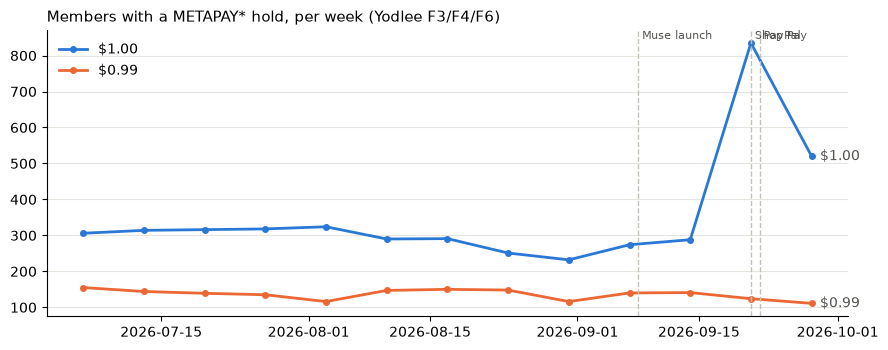

In [12]:
# Weekly members with a debit METAPAY* hold. The week of 09-28 is complete through 10-03 (6 of 7 days).
fig, ax = plt.subplots(figsize=(9, 3.6))
colors = {"$1.00": "#2a78d6", "$0.99": "#eb6834"}
for form, c in colors.items():
    s = by_amt[form]
    ax.plot(s.index, s.values, color=c, lw=2, marker="o", ms=4, label=form)
    ax.annotate(form, (s.index[-1], s.values[-1]), xytext=(6, 0), textcoords="offset points", va="center", color="#52514e")
for d, lab in [(LAUNCH, "Muse launch"), (SHOP_PAY, "Shop Pay"), (PAYPAL, "PayPal")]:
    ax.axvline(pd.Timestamp(d), color="#c3c2b7", lw=1, ls="--")
    ax.text(pd.Timestamp(d), ax.get_ylim()[1], f" {lab}", va="top", fontsize=8, color="#52514e")
ax.set_title("Members with a METAPAY* hold, per week (Yodlee F3/F4/F6)", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e0", lw=0.8)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()

In [13]:
# What happened next for the spike cohort: Muse charges, Link-agent purchases, and its AI profile against the baselines.
cols = ["web Muse charge (post-launch)", "Link agent (post-launch)", "OpenAI / ChatGPT", "Anthropic / Claude", "Cursor",
        "PayPal (PAYPAL / PP*)", "Shopify store (SP <store> / Shop Pay)"]
incidence.loc[cols, ["$1 hold, spike", "$1 hold, Jul-Aug", "control", "muse payers"]]

,"$1 hold, spike","$1 hold, Jul-Aug",control,muse payers
web Muse charge (post-launch),0.4,0.0,0.0,100.0
Link agent (post-launch),0.2,0.0,0.0,8.2
OpenAI / ChatGPT,19.3,8.9,2.9,47.5
Anthropic / Claude,13.0,1.3,0.6,42.6
Cursor,0.9,0.0,0.0,9.8
PayPal (PAYPAL / PP*),49.0,66.4,31.5,54.1
Shopify store (SP <store> / Shop Pay),41.6,42.4,21.4,47.5


## Conclusions (run 2026-10-08, cards complete through 2026-10-03)

**In short.** Stripe Link (`LINKAGNT*` / `LINK*`) is still the only card descriptor that marks an agent purchase. Muse checkouts through **PayPal (enabled 09-22) and Shop Pay (09-21) carry no distinguishable descriptor**: no new form, no agent token, and no measurable uplift in PayPal or Shopify spend. One new candidate signal did appear: a **$1.00 `METAPAY*` card-verification hold**, which surged from 09-21. It plausibly marks people adding a card to Meta for Muse, but that is not confirmed.

### 1. Muse payers' spend across agents
- **Cohort size.** 61 web Muse payers (`METAPAY META.COM` at $16 / $80) since launch.
- **Link-agent overlap.** **5 (8.2%)** also made a Stripe Link agent purchase, against 0.0% in the control (8,825 members). The purchases fall within -6 to +8 days of the member's first Muse charge, at Best Buy, AliExpress, Soundcore (`LINK* SP`), Speechify, Cloudflare and a state DMV.
- **AI profile.** Muse payers are AI-heavy: 48% pay OpenAI, 43% Anthropic and 10% Cursor, against 3%, 0.6% and 0% in the control.
- **Reverse direction.** Only **0.7%** of the 713 Link-agent users have a web Muse charge. Most Muse users are on the free tier or subscribe in-app, so the web charge cannot be used to tag Link-agent spend as Muse.

### 2. `LINKAGNT*` / `LINK*` is mostly, but not only, Muse
- **Before launch.** 24 members made Link-agent purchases before 09-08, from 08-03 (Gumroad, Amazon, 1-800-Flowers, First American), so other agents use Stripe's agent wallet too.
- **After launch.** New Link-agent users jumped with the launch: 0-13 a week before it, then 57, 108, 197 and 239 in the weeks from 09-07. Most volume is therefore launch-driven, but the series cannot be attributed to Muse alone.
- **Who uses it.** Link-agent users look like multi-agent power users: 31% OpenAI, 25% Anthropic and 8% Cursor, against 3%, 0.6% and 0% in the control.
- **Implication.** The app's agentic series is best read as "agent checkout via Stripe Link", led by Muse but not purely Muse, and as a floor.

### 3. PayPal (enabled in Muse 09-22): no identifiable descriptor
- **New keys.** 143 new PayPal descriptor keys appeared from 09-22 among Muse payers and Link-agent users. None is shared by more than 2 members, and all are ordinary merchants (Temu, DoorDash, Airbnb, DocuSign, Gap).
- **Agent tokens.** No PayPal row in any cohort contains `AGENT` or `AGNT`. The `META` / `LINK` / `MUSE` hits are LinkedIn, Starlink, Meta ads billed through PayPal (`PP*METAPLATFOR`, `PP*META*` transfers) and MuseScore, and all of them were present before 09-22.
- **Uplift.** The PayPal rate per active member did not move against the control after 09-21: lift 0.98 for Link-agent users and 1.08 for the $1-hold spike cohort. Muse payers show 1.15, but on 61 members that is within noise.
- **Agent purchases at PayPal merchants are visible only when Link pays.** For example, `LINK* PP*ATHENA ELITE WWW.LINK.COM`: these are already counted as Link agent.
- **Caveat.** This covers the cohorts plus a 1-in-2,000 control, not the whole panel. A panel-wide token-lift query over all PayPal rows (09-01 to 09-21 against 09-22 onward) was not run.

### 4. Shop Pay (enabled 09-21): same as PayPal
- **No shift.** Shopify-store spend did not shift against the control (lift 0.97 for Link-agent users, 0.93 for the spike cohort).
- **What is visible.** Only Link-paid purchases at Shopify stores (`LINK* SP <store>`) can be seen. The app's Shopify-store series was dropped on 2026-10-08 for this reason.

### 5. New lead: the $1.00 `METAPAY*` card-verification hold
- **Muse payers.** 6 of 61 Muse payers (10%) had a $1.00 `METAPAY*<code>` charge within -10 to +5 days of their first Muse charge, usually reversed the same day.
- **Panel-wide weekly series.**
  - The **$1.00 form** (members per week) ran at 232-324 from July to mid-September. It then rose to **835 in the week of 09-21** and 520 in the week of 09-28 (6 of 7 days complete).
  - The **99c form stayed flat** (111-155), so the rise is not a general Meta billing change.
  - The jump appears in **every feed**. F4 card went from 1-29 a week to 234.
  - Reversal credits rose with it, which fits card verification.
- **Timing.** The surge starts on **09-21/22, the Shop Pay and PayPal launch dates**, not on the 09-08 launch (the 09-07 week was flat at 274). It fades by early October.
- **Who the spike members are.** The 1,262 members first seen with a hold from 09-21 to 09-30 skew toward AI adoption: 19% pay OpenAI and 13% Anthropic, against 9% and 1.3% for the July-August holders and 3% and 0.6% in the control.
- **What they did next.** Few went on to a visible Muse outcome: 0.4% made a web Muse charge and 0.2% a Link-agent purchase.
- **Interpretation.** The most consistent reading is that these members added or verified a card in Meta Pay for Muse checkout, which now routes through Shop Pay and PayPal as well as Link. If so, their agent purchases would then post under ordinary merchant descriptors. The attribution is **not confirmed**: another Meta product requiring card verification over the same 10 days would look the same.

### What could identify Muse spend in the card panel
| Signal | Visible in cards? | Muse-specific? | Use |
|---|---|---|---|
| `LINKAGNT*` / `LINK*` (Stripe Link agent wallet) | Yes, non-Stripe merchants only | Mostly; other agents use it | Keep as the agentic floor (in the app) |
| PayPal checkout via Muse | No: ordinary `PAYPAL *<merchant>` | - | Not identifiable from descriptors |
| Shop Pay checkout via Muse | No: ordinary `SP <store>`, unless Link-paid | - | Not identifiable from descriptors |
| $1.00 `METAPAY*` hold above its ~300-a-week baseline | Yes, all feeds | Plausible, unconfirmed | Candidate indicator of Muse card set-up; validate before use |
| Web Muse charge (`METAPAY META.COM` $16 / $80) | Yes | Yes (by price) | Already in the app |

### Suggested next steps
1. **Validate the $1 hold.** Check NIQ e-receipts for Meta or Muse emails around 09-21 to 09-30 ("payment method added", Meta Pay or Muse checkout confirmations). Also check whether the spike repeats when Muse adds partners or markets.
2. **Look for agent-placed orders in e-receipts.** Search NIQ order-confirmation emails from PayPal and Shopify merchants for a Muse or Meta AI mention. Receipts may name the agent even though card descriptors do not.
3. **Panel-wide PayPal token lift.** Optionally, run it to close the cohort-only caveat in notebook section 5.